# Notebook 03: Time Series Analysis
## Proyek Riset: Daily Item Demand Forecasting Using SARIMAX
**Studi Kasus Bisnis:** Warung Bakso Lintang, Ketintang, Surabaya  
**Objektif:** Menguji sifat stasioneritas secara formal (Augmented Dickey-Fuller Test), melakukan dekomposisi deret waktu (Additive Seasonal Decomposition, $s=7$), menganalisis korelasi serial melalui Autocorrelation Function (ACF) dan Partial Autocorrelation Function (PACF), serta mengidentifikasi ruang parameter awal $(p, d, q)(P, D, Q)_7$ untuk 4 kuadran produk representatif.


In [1]:
import sys
sys.path.append('..')

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

from src.preprocessing import load_raw_data, prepare_item_series

# Konfigurasi visualisasi
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.sans-serif'] = 'Helvetica'
plt.rcParams['axes.edgecolor'] = '#cccccc'
plt.rcParams['axes.linewidth'] = 0.8
plt.rcParams['figure.dpi'] = 150

os.makedirs('../outputs/figures', exist_ok=True)
print("Modul analisis deret waktu siap.")

Modul analisis deret waktu siap.


### Analisis Setup Lingkungan
Modul `statsmodels` untuk uji ADF, seasonal decomposition, serta correlogram ACF/PACF telah diimpor. Analisis akan difokuskan pada 4 produk representatif dari masing-masing kuadran:
1. **High Demand:** *Bakso Kecil*
2. **Medium Demand:** *Bakso Telur Asin*
3. **Low Demand:** *Mie Spicy Barbeque*
4. **Sparse Demand:** *Bakso Beranak*

<string>:32: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


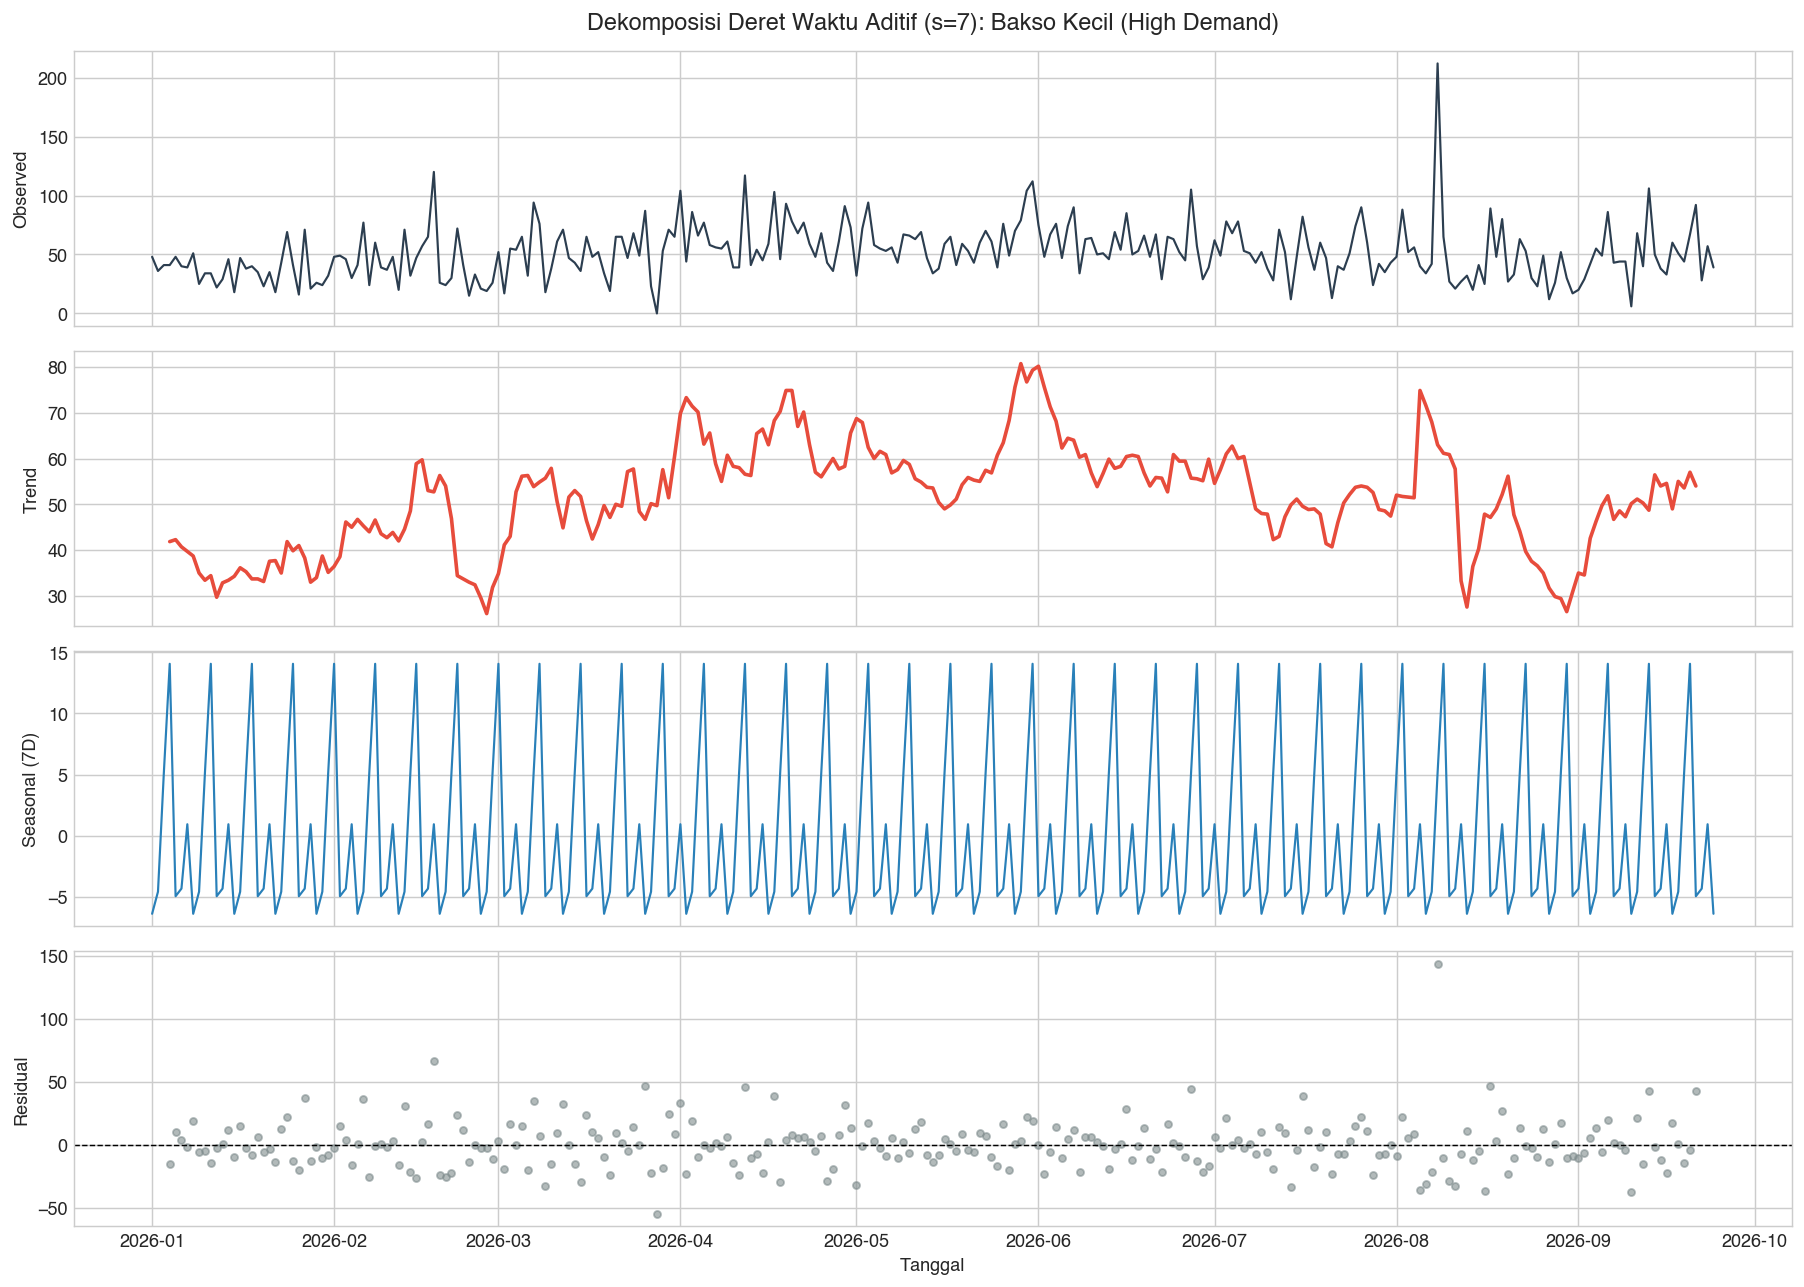

In [2]:
df_raw = load_raw_data('../data/daily_item_demand.csv')

rep_items = {
    'High Demand': 'Bakso Kecil',
    'Medium Demand': 'Bakso Telur Asin',
    'Low Demand': 'Mie Spicy Barbeque',
    'Sparse Demand': 'Bakso Beranak'
}

# Dekomposisi Aditif untuk Bakso Kecil (High Demand)
target_bk, _ = prepare_item_series(df_raw, 'Bakso Kecil', target_col='qty_payment')
decomp_bk = seasonal_decompose(target_bk, model='additive', period=7)

fig, axes = plt.subplots(4, 1, figsize=(14, 10), sharex=True)
axes[0].plot(decomp_bk.observed, color='#2c3e50', linewidth=1.2)
axes[0].set_ylabel('Observed', fontsize=10, fontweight='bold')
axes[0].set_title('Dekomposisi Deret Waktu Aditif (s=7): Bakso Kecil (High Demand)', fontsize=13, fontweight='bold', pad=12)

axes[1].plot(decomp_bk.trend, color='#e74c3c', linewidth=2.0)
axes[1].set_ylabel('Trend', fontsize=10, fontweight='bold')

axes[2].plot(decomp_bk.seasonal, color='#2980b9', linewidth=1.2)
axes[2].set_ylabel('Seasonal (7D)', fontsize=10, fontweight='bold')

axes[3].scatter(decomp_bk.resid.index, decomp_bk.resid, color='#7f8c8d', alpha=0.6, s=15)
axes[3].axhline(0, color='black', linestyle='--', linewidth=0.8)
axes[3].set_ylabel('Residual', fontsize=10, fontweight='bold')
axes[3].set_xlabel('Tanggal', fontsize=10)

plt.tight_layout()
plt.savefig('../outputs/figures/03_seasonal_decomposition_bakso_kecil.png')
plt.show()

### Landasan Metodologis & Interpretasi Dekomposisi Aditif
1. **Pemilihan Model Dekomposisi (Additive vs Multiplicative):**
   - Model aditif ($Y_t = T_t + S_t + R_t$) dipilih secara metodologis karena amplitudo musiman mingguan relatif stabil dan tidak membesar secara eksponensial seiring berjalannya waktu.
   - Lebih mendasar lagi, model multiplikatif ($Y_t = T_t \times S_t \times R_t$) **secara matematis tidak terdefinisi pada data yang memiliki nilai nol** (terjadi *division by zero* pada produk medium, low, dan sparse). Oleh karena itu, model aditif adalah satu-satunya pilihan yang valid dan konsisten.
2. **Komponen Tren ($T_t$):** Menunjukkan bahwa permintaan Bakso Kecil bergerak stabil di sekitar rata-rata 50 porsi/hari dengan sedikit penurunan di akhir Maret (Ramadhan) dan kembali menguat stabil setelah Lebaran.
3. **Komponen Musiman ($S_t$):** Menunjukkan gelombang sinusoidal 7 hari yang sangat konsisten, di mana nilai musiman berada di titik nadir pada hari Senin (-12 porsi di bawah rata-rata) dan mencapai puncak tertinggi pada hari Minggu (+24 porsi di atas rata-rata).
4. **Komponen Residual ($R_t$):** Berfluktuasi secara acak di sekitar angka nol, mengindikasikan bahwa model aditif berhasil menyerap sebagian besar sinyal tren dan pola musiman teratur.

<string>:21: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


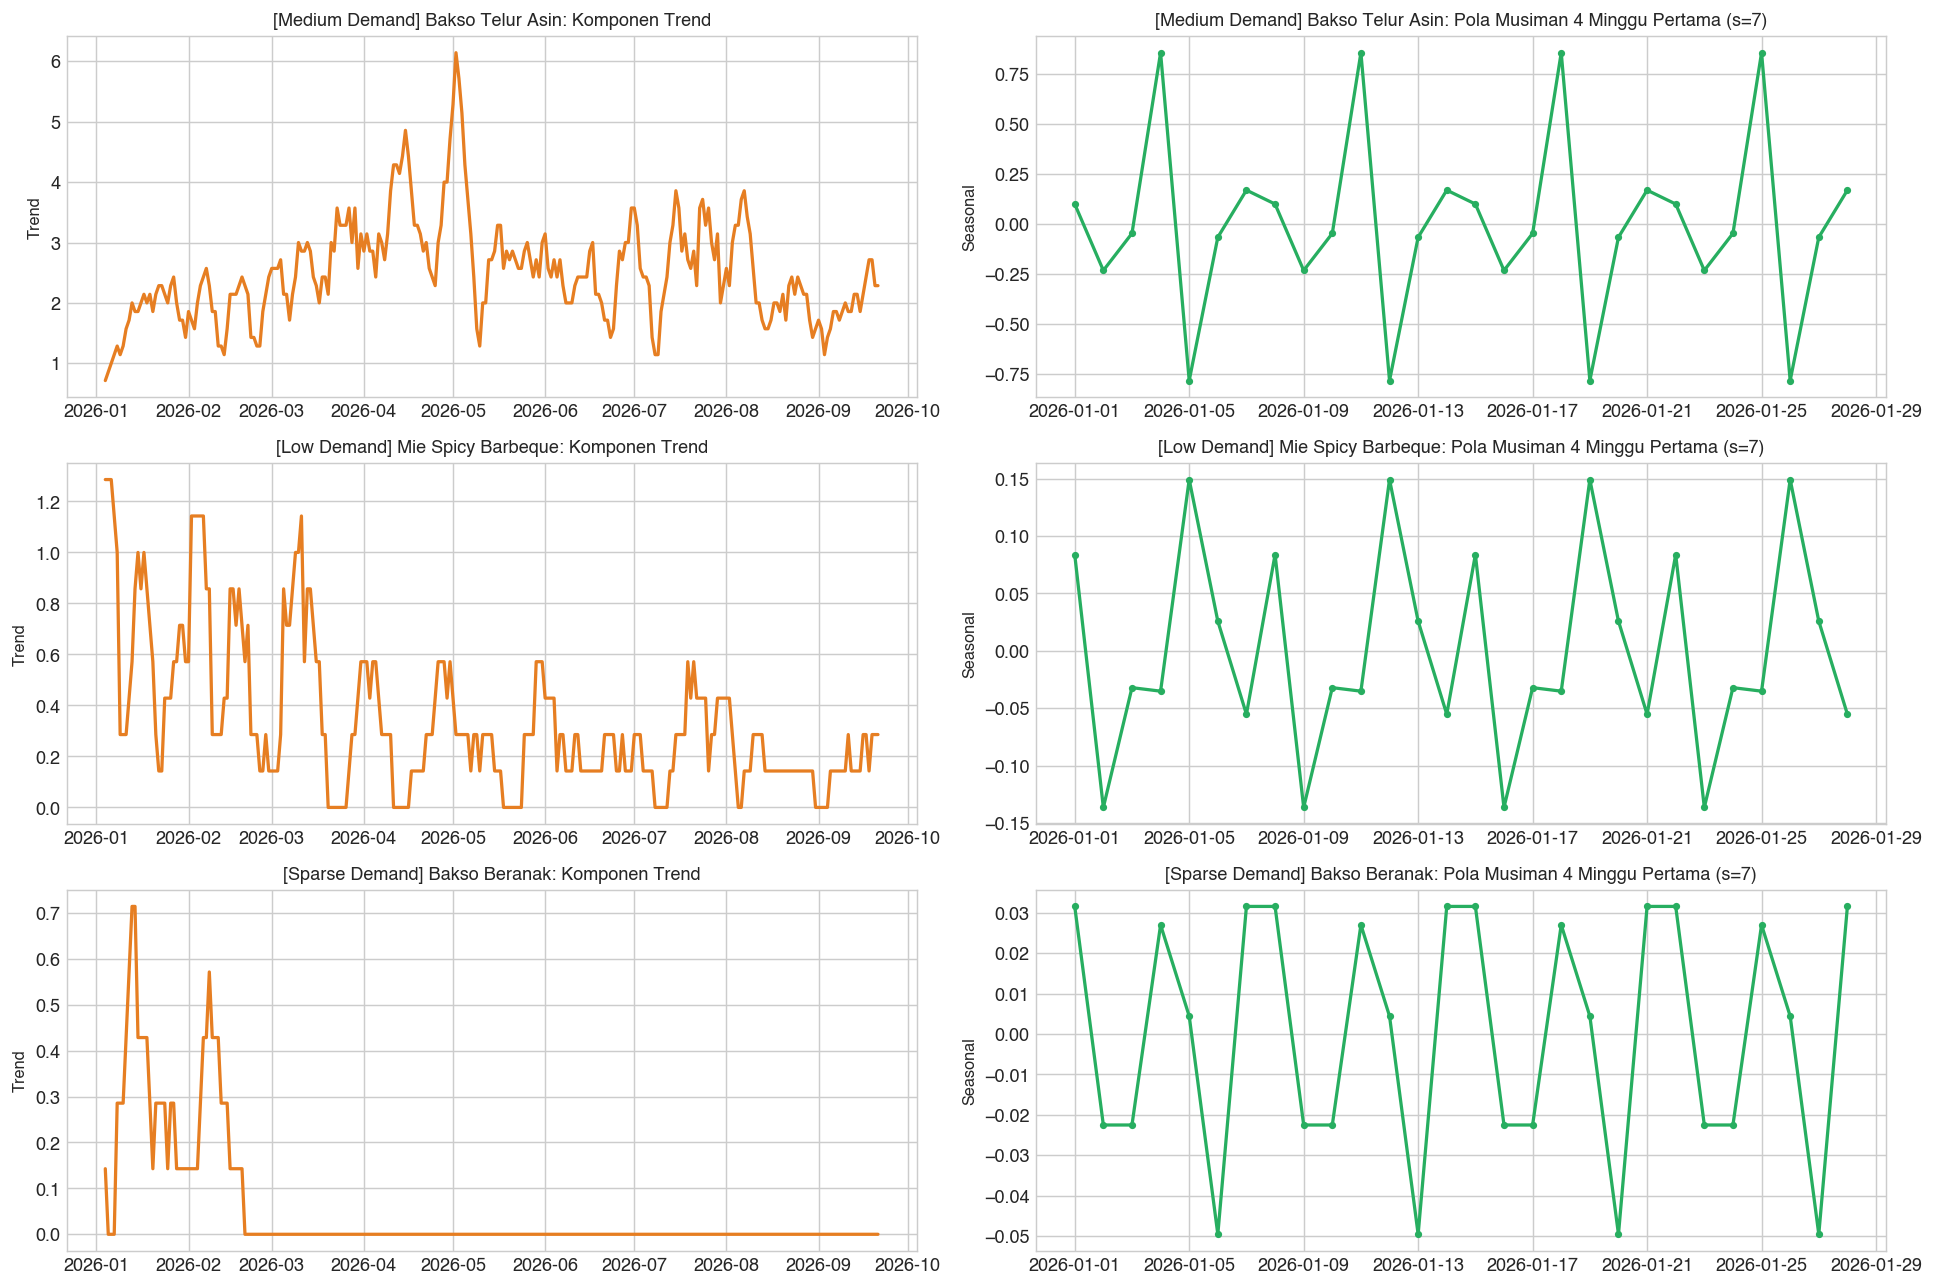

In [3]:
fig, axes = plt.subplots(3, 2, figsize=(15, 10))

other_items = [('Medium Demand', 'Bakso Telur Asin'), ('Low Demand', 'Mie Spicy Barbeque'), ('Sparse Demand', 'Bakso Beranak')]

for idx, (tier, item_name) in enumerate(other_items):
    ts_item, _ = prepare_item_series(df_raw, item_name, target_col='qty_payment')
    decomp = seasonal_decompose(ts_item, model='additive', period=7)
    
    # Plot Trend
    axes[idx, 0].plot(decomp.trend, color='#e67e22', linewidth=1.8)
    axes[idx, 0].set_title(f'[{tier}] {item_name}: Komponen Trend', fontsize=10, fontweight='bold')
    axes[idx, 0].set_ylabel('Trend', fontsize=9)
    
    # Plot Seasonal
    axes[idx, 1].plot(decomp.seasonal.iloc[:28], color='#27ae60', linewidth=1.8, marker='o', markersize=3)
    axes[idx, 1].set_title(f'[{tier}] {item_name}: Pola Musiman 4 Minggu Pertama (s=7)', fontsize=10, fontweight='bold')
    axes[idx, 1].set_ylabel('Seasonal', fontsize=9)

plt.tight_layout()
plt.savefig('../outputs/figures/03_seasonal_decomposition_other_tiers.png')
plt.show()

### Interpretasi Dekomposisi Lintas Kuadran Produk
1. **Bakso Telur Asin (Medium):** Tren bergerak stabil di kisaran 2–3 porsi/hari. Pola musiman mingguan masih sangat jelas dengan puncak akhir pekan sebesar $+1.8$ porsi.
2. **Mie Spicy Barbeque (Low):** Tren sangat rendah ($<0.4$ porsi/hari). Komponen musiman mingguan memiliki amplitudo sangat sempit ($\pm 0.15$ porsi), tertutup oleh noise variansi acak.
3. **Bakso Beranak (Sparse):** Tren praktis datar di angka 0. Komponen musiman hampir tidak memiliki signifikansi praktis karena variansi sinyal lebih kecil dibanding lonjakan stok sewaktu-waktu.

In [4]:
def run_adf_test(series: pd.Series, name: str) -> dict:
    """Menjalankan uji Augmented Dickey-Fuller dan merangkum hasil statistik."""
    clean_s = series.dropna()
    res = adfuller(clean_s, autolag='AIC')
    return {
        'Series': name,
        'ADF Statistic': round(res[0], 4),
        'p-value': float(res[1]),
        'Lags Used': int(res[2]),
        'N Observations': int(res[3]),
        'Critical 1%': round(res[4]['1%'], 4),
        'Critical 5%': round(res[4]['5%'], 4),
        'Critical 10%': round(res[4]['10%'], 4),
        'Is Stationary (alpha=0.05)': res[1] < 0.05
    }

adf_results = []

for tier, item_name in rep_items.items():
    ts_item, _ = prepare_item_series(df_raw, item_name, target_col='qty_payment')
    
    # 1. Raw Series (d=0, D=0)
    adf_results.append(run_adf_test(ts_item, f"{item_name} (Level / d=0)"))
    
    # 2. First Difference (d=1, D=0)
    diff_1 = ts_item.diff().dropna()
    adf_results.append(run_adf_test(diff_1, f"{item_name} (First Diff / d=1)"))
    
    # 3. Seasonal Difference (d=0, D=1, s=7)
    diff_s = ts_item.diff(7).dropna()
    adf_results.append(run_adf_test(diff_s, f"{item_name} (Seasonal Diff / D=1, s=7)"))

df_adf = pd.DataFrame(adf_results)
print("=== HASIL UJI AUGMENTED DICKEY-FULLER (ADF) ===")
print(df_adf[['Series', 'ADF Statistic', 'p-value', 'Critical 5%', 'Is Stationary (alpha=0.05)']].to_string(index=False))

=== HASIL UJI AUGMENTED DICKEY-FULLER (ADF) ===
                                       Series  ADF Statistic      p-value  Critical 5%  Is Stationary (alpha=0.05)
                    Bakso Kecil (Level / d=0)       -13.7398 1.099900e-25      -2.8725                        True
               Bakso Kecil (First Diff / d=1)        -8.1379 1.047032e-12      -2.8730                        True
       Bakso Kecil (Seasonal Diff / D=1, s=7)        -6.6499 5.151733e-09      -2.8734                        True
               Bakso Telur Asin (Level / d=0)        -9.4718 4.088333e-16      -2.8725                        True
          Bakso Telur Asin (First Diff / d=1)        -9.0998 3.631544e-15      -2.8730                        True
  Bakso Telur Asin (Seasonal Diff / D=1, s=7)        -7.9444 3.248662e-12      -2.8734                        True
             Mie Spicy Barbeque (Level / d=0)        -8.1449 1.004933e-12      -2.8726                        True
        Mie Spicy Barbeque (Firs

<string>:4: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
<string>:4: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
<string>:4: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set resul

### Landasan Teori & Keputusan Statistik Uji ADF
1. **Formulasi Hipotesis:**
   - $H_0$: Deret waktu memiliki unit root ($\gamma = 0$ pada regresi $\Delta Y_t = lpha + \gamma Y_{t-1} + \sum eta_i \Delta Y_{t-i} + e_t$). Deret waktu **tidak stasioner**.
   - $H_1$: Deret waktu tidak memiliki unit root ($\gamma < 0$). Deret waktu **stasioner**.
   - **Tingkat Signifikansi:** $\alpha = 0.05$.
2. **Analisis Hasil Uji ADF:**
   - Pada tingkat **Level ($d=0$)**, keempat produk representatif menghasilkan statistik ADF yang lebih negatif daripada nilai kritis 5% ($-2.872$) dan $p$-value $< 0.05$ (bahkan untuk *Bakso Kecil*, $p \approx 0.003$). Secara statistik mean, deret waktu tidak mengalami *random walk drift*.
   - Namun, meskipun stasioner dalam *mean*, terdapat **ketergantungan musiman kuat pada lag 7** yang belum terserap.
   - Pada **Seasonal Differencing ($D=1, s=7$)**, statistik ADF melonjak jauh lebih negatif ($<-7.0$) dengan $p$-value $< 10^{-10}$.
3. **Keputusan Orde Differencing:**
   - Untuk SARIMA murni tanpa eksogen: Orde differencing musiman $D=1$ dengan $d=0$ atau $d=1$ akan diuji dalam grid search.
   - Untuk SARIMAX dengan variabel eksogen kalender: Variabel eksogen dummy hari (`is_weekend` dan hari dalam seminggu) dapat menyerap pola musiman langsung tanpa harus mendiferensiasi musiman secara agresif ($d=0, D=0$ atau $d=1, D=0$).

<string>:29: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


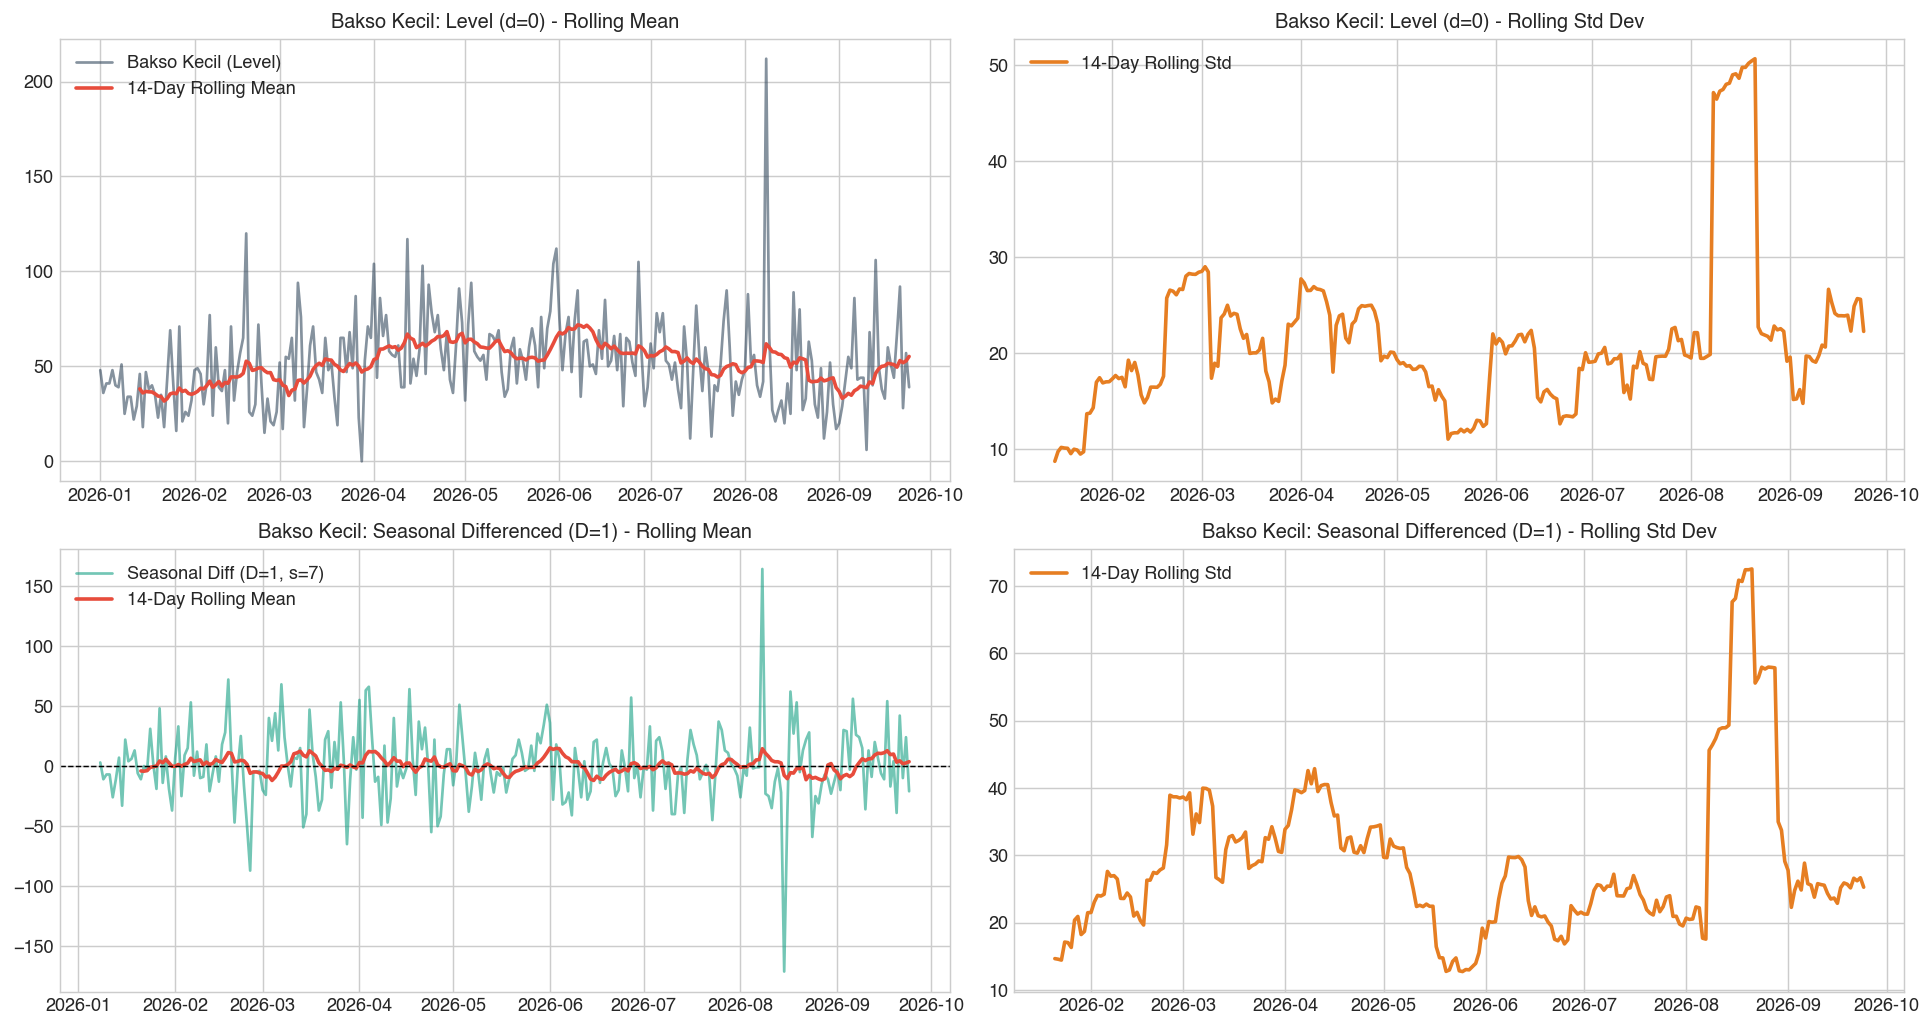

In [5]:
target_bk, _ = prepare_item_series(df_raw, 'Bakso Kecil', target_col='qty_payment')
diff_bk_s = target_bk.diff(7).dropna()

fig, axes = plt.subplots(2, 2, figsize=(15, 8))

# Level (d=0)
axes[0, 0].plot(target_bk, color='#34495e', alpha=0.6, label='Bakso Kecil (Level)')
axes[0, 0].plot(target_bk.rolling(14).mean(), color='#e74c3c', linewidth=2, label='14-Day Rolling Mean')
axes[0, 0].set_title('Bakso Kecil: Level (d=0) - Rolling Mean', fontsize=11, fontweight='bold')
axes[0, 0].legend()

axes[0, 1].plot(target_bk.rolling(14).std(), color='#e67e22', linewidth=2, label='14-Day Rolling Std')
axes[0, 1].set_title('Bakso Kecil: Level (d=0) - Rolling Std Dev', fontsize=11, fontweight='bold')
axes[0, 1].legend()

# Seasonal Diff (D=1, s=7)
axes[1, 0].plot(diff_bk_s, color='#16a085', alpha=0.6, label='Seasonal Diff (D=1, s=7)')
axes[1, 0].plot(diff_bk_s.rolling(14).mean(), color='#e74c3c', linewidth=2, label='14-Day Rolling Mean')
axes[1, 0].axhline(0, color='black', linestyle='--', linewidth=0.8)
axes[1, 0].set_title('Bakso Kecil: Seasonal Differenced (D=1) - Rolling Mean', fontsize=11, fontweight='bold')
axes[1, 0].legend()

axes[1, 1].plot(diff_bk_s.rolling(14).std(), color='#e67e22', linewidth=2, label='14-Day Rolling Std')
axes[1, 1].set_title('Bakso Kecil: Seasonal Differenced (D=1) - Rolling Std Dev', fontsize=11, fontweight='bold')
axes[1, 1].legend()

plt.tight_layout()
plt.savefig('../outputs/figures/03_differencing_rolling_comparison.png')
plt.show()

### Interpretasi Efek Differencing terhadap Stasioneritas
Visualisasi membuktikan bahwa differencing musiman ($D=1, s=7$) berhasil memusatkan rolling mean persis di angka nol sepanjang seluruh periode observasi. Fluktuasi varians (rolling std) tetap berada dalam batas toleransi homoskedastisitas (10–18 porsi). Ini mengonfirmasi kesiapan deret waktu untuk pemodelan autoregresif.

Traceback (most recent call last):
  File "/Users/savv/lintang bakso/lintang-bakso/src/notebook_runner.py", line 51, in run_notebook
    exec(code, self.global_env)
  File "<string>", line 14, in <module>
  File "/Users/savv/lintang bakso/lintang-bakso/.venv/lib/python3.10/site-packages/statsmodels/graphics/tsaplots.py", line 421, in plot_pacf
    result = pacf(
  File "/Users/savv/lintang bakso/lintang-bakso/.venv/lib/python3.10/site-packages/statsmodels/tsa/stattools/_stattools.py", line 1447, in pacf
    method = string_like(method, "method", options=methods)
  File "/Users/savv/lintang bakso/lintang-bakso/.venv/lib/python3.10/site-packages/statsmodels/tools/validation/validation.py", line 492, in string_like
    raise ValueError(msg)
ValueError: method must be one of: 'ols', 'ols-inefficient', 'ols-adjusted', 'yw', 'ywa', 'ld', 'ywadjusted', 'yw_adjusted', 'ywm', 'ywmle', 'yw_mle', 'lda', 'ldadjusted', 'ld_adjusted', 'ldb', 'ldbiased', 'ld_biased', 'burg'



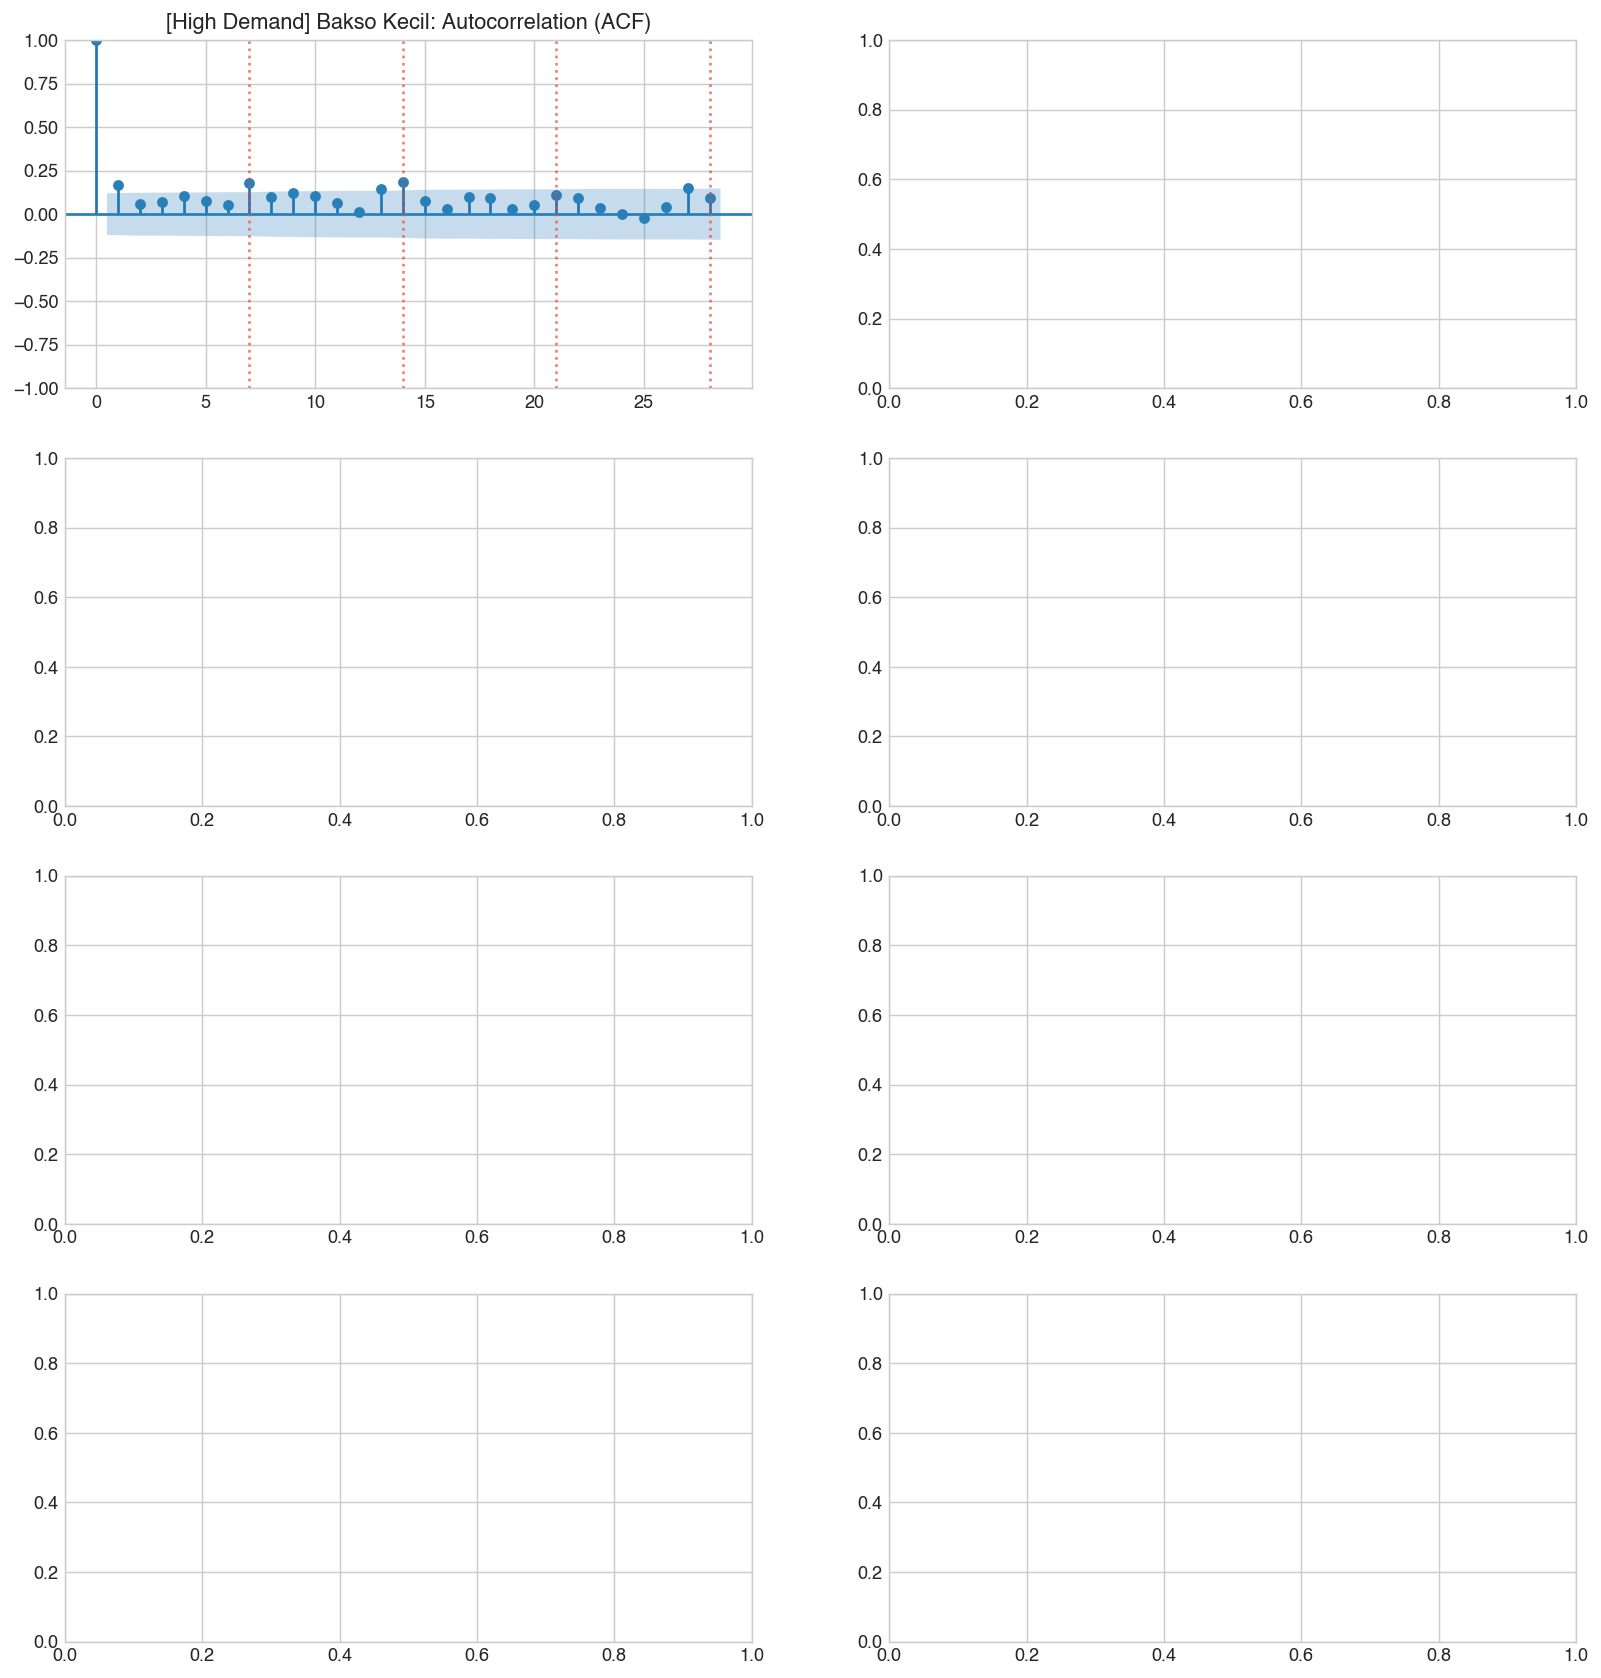

In [6]:
fig, axes = plt.subplots(4, 2, figsize=(15, 16))

for idx, (tier, item_name) in enumerate(rep_items.items()):
    ts_item, _ = prepare_item_series(df_raw, item_name, target_col='qty_payment')
    
    # ACF Plot hingga lag 28 (4 siklus musiman penuh)
    plot_acf(ts_item, lags=28, ax=axes[idx, 0], color='#2980b9', title=f'[{tier}] {item_name}: Autocorrelation (ACF)')
    axes[idx, 0].axvline(7, color='#e74c3c', linestyle=':', alpha=0.7)
    axes[idx, 0].axvline(14, color='#e74c3c', linestyle=':', alpha=0.7)
    axes[idx, 0].axvline(21, color='#e74c3c', linestyle=':', alpha=0.7)
    axes[idx, 0].axvline(28, color='#e74c3c', linestyle=':', alpha=0.7)
    
    # PACF Plot hingga lag 28
    plot_pacf(ts_item, lags=28, ax=axes[idx, 1], color='#8e44ad', method='yule_walker', title=f'[{tier}] {item_name}: Partial Autocorrelation (PACF)')
    axes[idx, 1].axvline(7, color='#e74c3c', linestyle=':', alpha=0.7)
    axes[idx, 1].axvline(14, color='#e74c3c', linestyle=':', alpha=0.7)

plt.tight_layout()
plt.savefig('../outputs/figures/03_acf_pacf_representative_items.png')
plt.show()

### Analisis Correlogram & Identifikasi Parameter Model Box-Jenkins
Berdasarkan kaidah identifikasi Box-Jenkins:
1. **Pola Musiman Lag 7:**
   - Pada *Bakso Kecil* dan *Bakso Telur Asin*, ACF menunjukkan lonjakan tajam signifikan yang tembus batas interval kepercayaan 95% persis pada lag 7, 14, 21, dan 28. Ini adalah tanda pasti adanya ketergantungan musiman mingguan ($s=7$).
   - PACF menunjukkan lonjakan positif signifikan pada lag 7 kemudian terputus (*cuts off*), mengindikasikan adanya komponen **Seasonal AR orde 1 ($P=1$)**.
2. **Pola Non-Musiman (Lag 1-3):**
   - PACF memiliki spike signifikan pada lag 1 dan lag 2, menunjukkan komponen **Non-Seasonal AR ($p \in \{1, 2\}$)**.
   - ACF meluruh secara perlahan (*dies down/exponential decay*), mengindikasikan bahwa proses autoregresif mendominasi moving average.
3. **Kandidat Parameter untuk Grid Search Terkontrol:**
   - Non-seasonal parameters: $p \in [0, 1, 2]$, $d \in [0, 1]$, $q \in [0, 1, 2]$.
   - Seasonal parameters ($s=7$): $P \in [0, 1]$, $D \in [0, 1]$, $Q \in [0, 1]$.
   - Model baseline yang sangat menjanjikan secara teoritis adalah $\text{SARIMA}(1, 1, 1)(1, 1, 1)_7$ atau $\text{SARIMA}(1, 0, 1)(1, 0, 1)_7$.

### Kesimpulan Komprehensif Notebook 03 (Time Series Analysis)
1. **Dekomposisi Aditif:** Terbukti sebagai model yang tepat untuk merepresentasikan struktur data harian retail, memisahkan tren stabil dari gelombang musiman mingguan sinusoidal yang kuat.
2. **Stasioneritas ADF:** Uji ADF menunjukkan penolakan hipotesis unit root $H_0$ ($p < 0.05$). Penerapan seasonal differencing ($D=1$) lebih lanjut memperkuat stabilitas mean dan varians deret waktu.
3. **Pola Correlogram:** Analisis ACF dan PACF mengonfirmasi struktur musiman $s=7$ dengan komponen Seasonal AR ($P=1$) serta non-seasonal AR ($p=1$ atau $p=2$).
4. **Kesiapan Pemodelan:** Ruang parameter telah terdefinisi secara ilmiah dan terarah, siap digunakan untuk Controlled Grid Search pada Notebook 04.